<a href="https://colab.research.google.com/github/claramanolache/DeepLearning/blob/main/Generative_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Firewall anylisis
building a model that preforms anomaly detection on network traffic

In [1]:
!pip install opendatasets
!pip install legacy-cgi

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import keras
import torch
import torch.nn as nn
from torch.utils import data

from sklearn import model_selection
from sklearn import ensemble
from sklearn import metrics
from sklearn import dummy

In [9]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

In [10]:
seed = 42
np.random.seed(seed)
torch.manual_seed(seed)

##Helper Functions

In [12]:
def init_params(module):
    if isinstance(module, nn.Linear):
        nn.init.kaiming_uniform_(module.weight)
        nn.init.zeros_(module.bias)

##importing dataset

In [4]:
od.download(
    "https://www.kaggle.com/datasets/tunguz/internet-firewall-data-set")

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: claramanolache
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/tunguz/internet-firewall-data-set


100%|██████████| 754k/754k [00:00<00:00, 80.4MB/s]

In [5]:
import os

folder = "internet-firewall-data-set"

print(os.listdir(folder))

['log2.csv']


In [6]:
file =('internet-firewall-data-set/log2.csv')
df = pds.read_csv(file)

In [7]:
df.shape

(65532, 12)

In [8]:
df.head()

,Source Port,Destination Port,NAT Source Port,NAT Destination Port,Action,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received
0,57222,53,54587,53,allow,177,94,83,2,30,1,1
1,56258,3389,56258,3389,allow,4768,1600,3168,19,17,10,9
2,6881,50321,43265,50321,allow,238,118,120,2,1199,1,1
3,50553,3389,50553,3389,allow,3327,1438,1889,15,17,8,7
4,50002,443,45848,443,allow,25358,6778,18580,31,16,13,18


##Formating/splitting dataset

In [14]:
X = df.drop(columns=["Action"])
actions = df["Action"].copy()

###encoding destination ports by range

In [15]:
df['Destination Port'].nunique()

3273

<Axes: xlabel='Destination Port'>

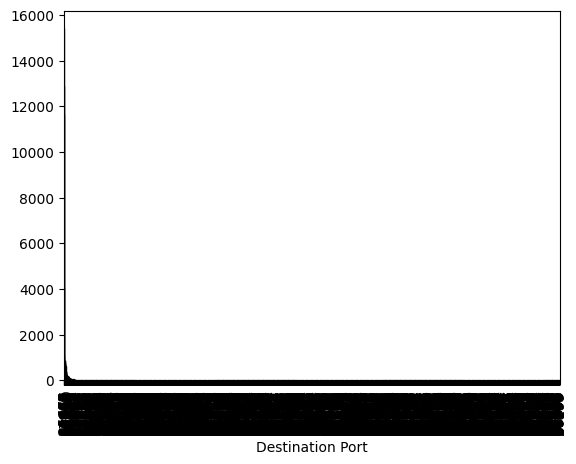

In [16]:
df['Destination Port'].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')

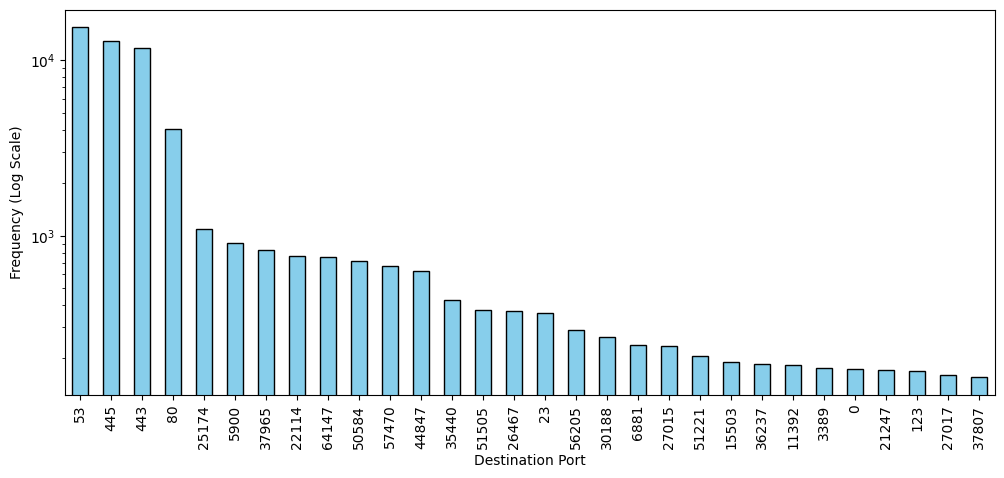

In [17]:
df["Destination Port"].value_counts().head(30).plot(
    kind="bar",
    color="skyblue",
    edgecolor="black",
    figsize=(12, 5),
    logy=True
)

plt.ylabel("Frequency (Log Scale)")
plt.show()

going to encode in ranges

In [18]:
common_ports = (
    X["Destination Port"]
    .value_counts()
    .head(12)
    .index.tolist()
)

In [19]:
def categorize_port(port, common_ports):
    if port in common_ports:
        return str(port)
    elif port == 0:
        return "reserved"
    elif port <= 1023:
        return "well_known"
    elif port <= 49151:
        return "registered"
    else:
        return "dynamic"

In [20]:
X["Destination Port"] = X["Destination Port"].apply(
    lambda port: categorize_port(port, common_ports)
)

In [21]:
X = pd.get_dummies(
    X,
    columns=["Destination Port"],
    dtype=float
)

In [22]:
X.head()

,Source Port,NAT Source Port,NAT Destination Port,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received,...,Destination Port_50584,Destination Port_53,Destination Port_57470,Destination Port_5900,Destination Port_64147,Destination Port_80,Destination Port_dynamic,Destination Port_registered,Destination Port_reserved,Destination Port_well_known
0,57222,54587,53,177,94,83,2,30,1,1,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,56258,56258,3389,4768,1600,3168,19,17,10,9,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,6881,43265,50321,238,118,120,2,1199,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,50553,50553,3389,3327,1438,1889,15,17,8,7,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,50002,45848,443,25358,6778,18580,31,16,13,18,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [24]:
X.shape

(65532, 26)

###Encoding source ports

In [25]:
df['Source Port'].nunique()

22724

In [26]:
common_source_ports = (
    X["Source Port"]
    .value_counts()
    .head(12)
    .index.tolist()
)

X["Source Port"] = X["Source Port"].apply(
    lambda port: categorize_port(port, common_source_ports)
)

X = pd.get_dummies(
    X,
    columns=["Source Port"],
    dtype=float
)

X.head()

,NAT Source Port,NAT Destination Port,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received,Destination Port_22114,...,Source Port_443,Source Port_49418,Source Port_50584,Source Port_5588,Source Port_57470,Source Port_58638,Source Port_6881,Source Port_dynamic,Source Port_registered,Source Port_well_known
0,54587,53,177,94,83,2,30,1,1,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,56258,3389,4768,1600,3168,19,17,10,9,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,43265,50321,238,118,120,2,1199,1,1,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,50553,3389,3327,1438,1889,15,17,8,7,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,45848,443,25358,6778,18580,31,16,13,18,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [30]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Standardize classes: 'allow' is normal (0), everything else is anomalous (1)
y_labels = (actions != 'allow').astype(int)

# Take a subset of 20,000 samples
X_sub = X.iloc[:20000].copy()
y_sub = y_labels.iloc[:20000].copy()

# Separate normal (0) and anomalous (1) indices
normal_indices = y_sub[y_sub == 0].index
anomaly_indices = y_sub[y_sub == 1].index

# Split normal indices into 60% for training, 40% for validation/testing
train_normal_idx, rem_normal_idx = train_test_split(
    normal_indices,
    test_size=0.40,
    random_state=seed
)

# Training data: 60% of normal traffic (only normal behavior)
X_train = X_sub.loc[train_normal_idx]
y_train = y_sub.loc[train_normal_idx]

# Collect the remaining normals and all anomalies for a mixed validation and test set
mixed_rem_idx = rem_normal_idx.union(anomaly_indices)
X_rem = X_sub.loc[mixed_rem_idx]
y_rem = y_sub.loc[mixed_rem_idx]

# Split the remaining mixed pool equally into validation (20% of total) and test (20% of total)
X_val, X_test, y_val, y_test = train_test_split(
    X_rem, y_rem,
    test_size=0.5,
    random_state=seed,
    stratify=y_rem
)

print(f"Training set (Normal only): {X_train.shape}, {y_train.value_counts().to_dict()}")
print(f"Validation set (Mixed): {X_val.shape}, {y_val.value_counts().to_dict()}")
print(f"Test set (Mixed): {X_test.shape}, {y_test.value_counts().to_dict()}")

Training set (Normal only): (6611, 40), {0: 6611}
Validation set (Mixed): (6694, 40), {1: 4490, 0: 2204}
Test set (Mixed): (6695, 40), {1: 4491, 0: 2204}


###rest of splitting

##Autencoders

In [13]:
encoder = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 2)
)